# VRP (Time/Position-Indexed) → QUBO (Penalty Formulation)

This notebook teaches how to:

1. Define **time/position-indexed** Vehicle Routing Problem variables.
2. Write a constrained **VRP** model using those variables.
3. Convert constraints into **QUBO penalties** (squared terms), including capacity using slack bits.
4. Build the full QUBO energy: **travel cost + penalties**.
5. Work a tiny numeric example, and expand at least one penalty symbolically.

---

## Big idea (intuitive)
- We have a **depot (0)** and **customers (1..n)**.
- Each vehicle picks an ordered sequence of stops.
- We model the sequence by **steps**: \(t=0,1,\dots,T\).
- QUBO needs **binary variables** and **one unconstrained quadratic objective**.
- So we **absorb constraints** into the objective via penalties.

We include a **dummy node** \(\emptyset\) to represent an unused step (route ended early).

In [11]:
# Imports
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import networkx as nx
import json

np.set_printoptions(linewidth=120, suppress=True)

## 1) Create Instance

In the VRP without capacity we only need:

- Travel costs $ c_{ij} $

### Define Number of Vehicles

In [21]:
# --- User parameters (edit these) ---

n_customers = 5   # number of customers (nodes 1..n)
K = 2             # number of vehicles
Q_capacity = 5    # capacity per vehicle
T = None          # if None, uses T = n_customers (steps 0..T)
seed = 0          # RNG seed for generating an example cost matrix

demands = None

lambdas = {
    "step": 10,
    "visit": 10,
    "start": 20,
    "no_depot_mid": 5,
    "contig": 20
}

### Random Instance Generator


We generate a symmetric cost matrix using random 2D coordinates and Euclidean distance.

In [22]:
def generate_instance(n_customers, seed=0):
    rng = np.random.default_rng(seed)

    n = n_customers + 1

    # -------------------------
    # 1) Coordenadas
    # -------------------------
    coords = rng.uniform(0, 10, size=(n, 2))

    # distância euclidiana
    dist = np.linalg.norm(coords[:, None, :] - coords[None, :, :], axis=-1)
    distance = np.rint(dist * 10).astype(int)

    # -------------------------
    # 2) Congestionamento
    # -------------------------
    congestion = rng.uniform(0.8, 2.5, size=(n, n))

    # simetrizar
    congestion = (congestion + congestion.T) / 2

    # tempo correlacionado com distância
    time = dist * congestion**2
    time = np.rint(time * 100).astype(int)

    # -------------------------
    # 3) Risco (independente)
    # -------------------------
    risk = rng.integers(1, 10, size=(n, n))
    risk = (risk + risk.T) // 2

    # -------------------------
    # 4) Custo/pedágio (independente)
    # -------------------------
    cost = rng.integers(5, 50, size=(n, n))
    cost = (cost + cost.T) // 2

    # -------------------------
    # remover diagonais
    # -------------------------
    for M in [distance, time, risk, cost]:
        np.fill_diagonal(M, 0)

    return distance, time, risk, cost, coords


# -------------------------
# Example
# -------------------------
dist_matrix, time_matrix, risk_matrix, cost_matrix, coords = generate_instance(n_customers, seed)

print("Distance matrix")
print(dist_matrix)

print("\nTime matrix")
print(time_matrix)

print("\nRisk matrix")
print(risk_matrix)

print("\nCost matrix")
print(cost_matrix)

instances = {
    "Distance": dist_matrix,
    "Time": time_matrix,
    "Risk": risk_matrix,
    "Cost": cost_matrix
}

Distance matrix
[[  0  65  67  46  67  32]
 [ 65   0 118  91 105  78]
 [ 67 118   0  28  27  91]
 [ 46  91  28   0  22  76]
 [ 67 105  27  22   0  97]
 [ 32  78  91  76  97   0]]

Time matrix
[[   0  760 2518 1085 2546 1002]
 [ 760    0 1565 1391 4733 2078]
 [2518 1565    0  844 1282 2586]
 [1085 1391  844    0  517 2506]
 [2546 4733 1282  517    0 1558]
 [1002 2078 2586 2506 1558    0]]

Risk matrix
[[0 2 5 8 5 7]
 [2 0 6 8 2 3]
 [5 6 0 4 8 7]
 [8 8 4 0 4 2]
 [5 2 8 4 0 5]
 [7 3 7 2 5 0]]

Cost matrix
[[ 0 23 31 27 19 22]
 [23  0 25 28 43 36]
 [31 25  0 47  9 25]
 [27 28 47  0 22 38]
 [19 43  9 22  0 27]
 [22 36 25 38 27  0]]


### Visualize Graph

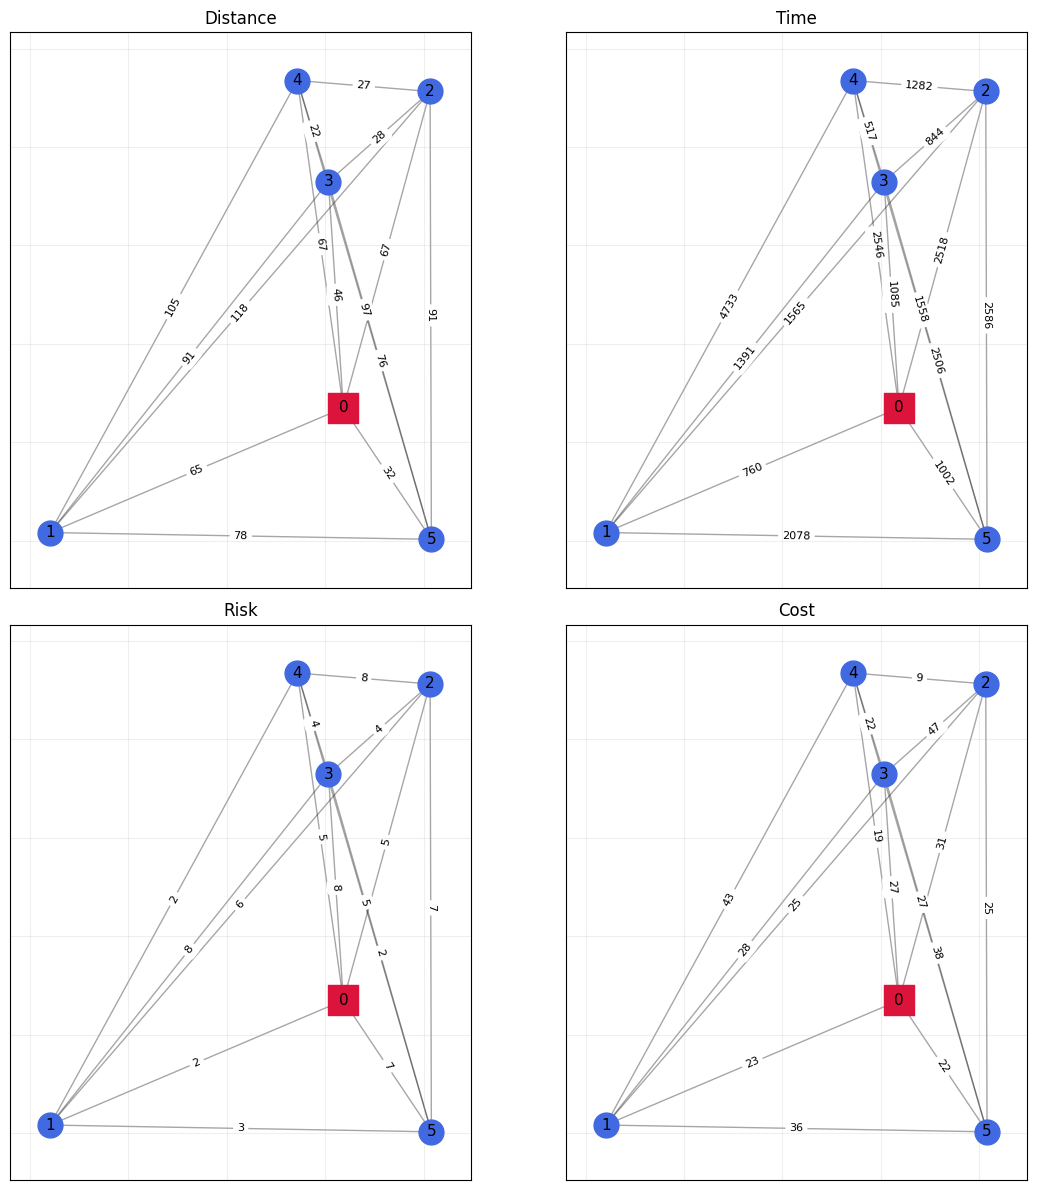

In [23]:
def draw_vrp_graph_networkx(coords, c_core, title="VRP graph",
                            cost_threshold=None,
                            show_weights=True, ax=None):
    coords = np.asarray(coords)
    c = np.asarray(c_core)
    n_nodes = coords.shape[0]

    G = nx.Graph()
    for i in range(n_nodes):
        G.add_node(i, pos=(coords[i,0], coords[i,1]))

    for i in range(n_nodes):
        for j in range(i+1, n_nodes):
            if cost_threshold is None or c[i,j] <= cost_threshold:
                G.add_edge(i, j, weight=int(c[i,j]))

    pos = {i: (coords[i,0], coords[i,1]) for i in range(n_nodes)}

    if ax is None:
        fig, ax = plt.subplots(figsize=(7,7))

    nx.draw_networkx_nodes(G, pos, nodelist=[0],
                           node_color="crimson", node_shape="s", node_size=450, ax=ax)
    nx.draw_networkx_nodes(G, pos,
                           nodelist=list(range(1, n_nodes)),
                           node_color="royalblue", node_shape="o", node_size=320, ax=ax)

    nx.draw_networkx_edges(G, pos, alpha=0.35, width=1.0, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=11, font_color="black", ax=ax)

    if show_weights:
        edge_labels = {(u,v): d["weight"] for u,v,d in G.edges(data=True)}
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8, ax=ax)

    ax.set_title(title)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for ax, (name, matrix) in zip(axes.flatten(), instances.items()):
    draw_vrp_graph_networkx(
        coords,
        matrix,
        title=name,
        ax=ax
    )

plt.tight_layout()
plt.show()

## 2) Sets and notation

- Depot: node **0**
- Customers: $C = \{1,\dots,n\}$
- Dummy empty node: $\emptyset$
- Extended node set: $N = \{0\}\cup C \cup \{\emptyset\}$

Vehicles: $k\in\{1,\dots,K\}$

Steps: $t\in\{0,\dots,T\}$. We use $T=n$ if not specified.

Binary variable:
$
  x_{i,k,t}=1 \iff \text{vehicle }k\text{ is at node }i\text{ at step }t.
$

In [24]:
def build_sets(n_customers, T=None):
    if T is None:
        T = n_customers
    depot = 0
    customers = list(range(1, n_customers+1))
    empty = '∅'
    N = [depot] + customers + [empty]
    return depot, customers, empty, N, T


depot, C, EMPTY, N, T_eff = build_sets(n_customers, T)
print('Depot:', depot)
print('Customers:', C)
print('Empty symbol:', EMPTY)
print('N:', N)
print('T:', T_eff, '=> steps t=0..T')

Depot: 0
Customers: [1, 2, 3, 4, 5]
Empty symbol: ∅
N: [0, 1, 2, 3, 4, 5, '∅']
T: 5 => steps t=0..T


## 3) Variable indexing: map $ x_{ij} $ into a single QUBO vector

A QUBO uses one big binary vector $z$. We'll map each variable to an index.

### Slack bits for capacity
For each vehicle $k$, add slack $s_k$ so that:
$$
\sum_{t=1}^{T}\sum_{i\in C} q_i x_{i,k,t} + s_k = Q
$$
Encode slack in binary:
$$
 s_k = \sum_{b=0}^{B-1}2^b\,w_{k,b}
$$
where $B=\lceil\log_2(Q+1)\rceil$.


In [25]:
def variable_indexing():
    x_index = {}
    idx = 0

    for k in range(1, K+1):
        for t in range(0, T_eff+1):
            for i in N:
                x_index[(i,k,t)] = idx
                idx += 1

    return x_index, idx

x_index, n_vars = variable_indexing()
print('Total binary variables:', n_vars)
print('x variables:', len(x_index), ' = |N|*K*(T+1) =', len(N)*K*(T_eff+1))

Total binary variables: 84
x variables: 84  = |N|*K*(T+1) = 84


## 4) QUBO construction helpers


We construct an energy:
$$
H(z) = z^T Q z + \text{constant}
$$

We use helper functions to add:
- linear terms $a z_i$ (store as diagonal)
- quadratic terms $b z_i z_j$ (store in upper triangle)
- squared penalties of affine expressions $(\sum a_i z_i + c)^2$


In [26]:
def add_quadratic(Qmat, i, j, coeff):
    # Store in upper triangle
    if i <= j:
        Qmat[i, j] += coeff
    else:
        Qmat[j, i] += coeff


def add_linear(Qmat, i, coeff):
    # Linear coeff*z_i stored on diagonal
    Qmat[i, i] += coeff


def square_of_affine_to_qubo(Qmat, var_coeffs, constant, weight=1.0):
    # Adds weight*(sum_i a_i z_i + constant)^2
    # Expansion: weight*( z^T (a a^T) z + 2*constant*(a^T z) + constant^2 )
    # For binary z, keep all terms in QUBO form.

    items = list(var_coeffs.items())

    # Quadratic + diagonal from (a^T z)^2
    for p, (i, ai) in enumerate(items):
        add_linear(Qmat, i, weight * (ai * ai))  # ai^2 z_i
        for j, aj in items[p+1:]:
            add_quadratic(Qmat, i, j, weight * (2 * ai * aj))

    # Linear from 2*constant*(a^T z)
    for i, ai in items:
        add_linear(Qmat, i, weight * (2 * constant * ai))

    # Constant contribution
    return weight * (constant * constant)

## 5) Build the full QUBO (cost + penalties)


### Conventions used
- Start at depot: enforce $x_{0,k,0}=1$ using a penalty.
- Forbid depot at steps $t\ge1$ (optional) via a linear penalty.
- Use $\emptyset$ for unused steps.
- Enforce contiguity: once $\emptyset$, always $\emptyset$.
- Add return-to-depot cost when transitioning into $\emptyset$.

In [27]:
def build_qubo(c_core):
    max_cost_hint = np.max(c_core) * len(c_core)
    lambdas_adjusted = {key: value*max_cost_hint for key, value in lambdas.items()}
    
    x_index, n_vars = variable_indexing()
    Qmat = np.zeros((n_vars, n_vars), dtype=float)
    const = 0.0

    # Cost function on N: define costs to/from EMPTY as 0
    def cost(i, j):
        if i == EMPTY or j == EMPTY:
            return 0.0
        return float(c_core[int(i), int(j)])

    # 6.1 Travel cost for consecutive steps t -> t+1
    for k in range(1, K+1):
        for t in range(0, T_eff):
            for i in N:
                for j in N:
                    if j == i:
                        continue
                    cij = cost(i, j)
                    if cij != 0:
                        ii = x_index[(i,k,t)]
                        jj = x_index[(j,k,t+1)]
                        add_quadratic(Qmat, ii, jj, cij)

    # 6.2 Return-to-depot when transitioning into EMPTY
    for k in range(1, K+1):
        for t in range(0, T_eff):
            for i in [depot] + C:
                ci0 = cost(i, depot)
                if ci0 != 0:
                    ii = x_index[(i,k,t)]
                    jj = x_index[(EMPTY,k,t+1)]
                    add_quadratic(Qmat, ii, jj, ci0)

    # 6.3 One node per step: (sum_i x_{i,k,t} - 1)^2
    for k in range(1, K+1):
        for t in range(0, T_eff+1):
            var_coeffs = {x_index[(i,k,t)]: 1.0 for i in N}
            const += square_of_affine_to_qubo(Qmat, var_coeffs, constant=-1.0, weight=lambdas_adjusted["step"])

    # 6.4 Each customer visited exactly once: (sum_{k,t} x_{i,k,t} - 1)^2
    for i in C:
        var_coeffs = {x_index[(i,k,t)]: 1.0 for k in range(1, K+1) for t in range(1, T_eff+1)}
        const += square_of_affine_to_qubo(Qmat, var_coeffs, constant=-1.0, weight=lambdas_adjusted["visit"])

    # 6.5 Start depot penalty: (x_{0,k,0} - 1)^2
    for k in range(1, K+1):
        var_coeffs = {x_index[(depot,k,0)]: 1.0}
        const += square_of_affine_to_qubo(Qmat, var_coeffs, constant=-1.0, weight=lambdas_adjusted["start"])

    # 6.6 Forbid depot at steps 1..T (linear)
    for k in range(1, K+1):
        for t in range(1, T_eff+1):
            add_linear(Qmat, x_index[(depot,k,t)], lambdas_adjusted["no_depot_mid"])

    # 6.7 Contiguity of EMPTY: penalize x_EMPTY(k,t)=1 and x_EMPTY(k,t+1)=0
    # Penalty term: lambda * x_t*(1 - x_{t+1}) = lambda*x_t - lambda*x_t*x_{t+1}
    for k in range(1, K+1):
        for t in range(0, T_eff):
            xt = x_index[(EMPTY,k,t)]
            xt1 = x_index[(EMPTY,k,t+1)]
            add_linear(Qmat, xt, lambdas_adjusted["contig"])
            add_quadratic(Qmat, xt, xt1, -lambdas_adjusted["contig"])

    info = {
        "depot": depot,
        "customers": C,
        "EMPTY": EMPTY,
        "N": N,
        "T": T_eff,
        "coords": coords,
        "c_core": c_core,
        "x_index": x_index,
        "n_vars": n_vars,
        "lambdas": lambdas_adjusted,
    }

    return Qmat, const, info


# -------------------------
# Build ALL QUBOs (NEW)
# -------------------------
instances = {
    "distance": dist_matrix,
    "time": time_matrix,
    "risk": risk_matrix,
    "cost": cost_matrix
}

qubo_models = {}

for name, matrix in instances.items():
    Qmat, const, info = build_qubo(matrix)

    qubo_models[name] = {
        "Q": Qmat,
        "const": const,
        "info": info
    }

    print(f"\n{name.upper()} QUBO")
    print("Variables:", info["n_vars"])
    print("Constant:", const)
    print("Max |Q| coeff:", np.max(np.abs(Qmat)))


DISTANCE QUBO
Variables: 84
Constant: 148680.0
Max |Q| coeff: 21240.0

TIME QUBO
Variables: 84
Constant: 5963580.0
Max |Q| coeff: 851940.0

RISK QUBO
Variables: 84
Constant: 10080.0
Max |Q| coeff: 1440.0

COST QUBO
Variables: 84
Constant: 59220.0
Max |Q| coeff: 8460.0


# 6) Exploring Solution


Find optimal solution by exhaustive search and check candidate solutions against it.

### Solve by Brute Force

#### Parallel

In [69]:
from itertools import product
from multiprocessing import Pool, cpu_count
from tqdm import tqdm

def solve_chunk(args):
    Q, const, fixed_bits, n = args
    
    k = len(fixed_bits)
    best_val = np.inf
    best_x_list = []
    
    for tail in product([0, 1], repeat=n - k):
        bits = fixed_bits + tail
        x = np.array(bits)
        val = x @ Q @ x + const
        
        if val < best_val - 1e-10:
            best_val = val
            best_x_list = [x]
        elif abs(val - best_val) < 1e-10:
            best_x_list.append(x)
    
    return best_val, best_x_list


def brute_force_parallel(Q, const, k=4):
    n = len(Q)
    
    prefixes = list(product([0, 1], repeat=k))
    args = [(Q, const, prefix, n) for prefix in prefixes]
    
    with Pool(cpu_count()) as pool:
        results = []
    
        for result in tqdm(pool.imap_unordered(solve_chunk, args),
						total=len(args),
						desc="Processing chunks"):
            results.append(result)
    
    # 🔥 Combinar resultados
    global_best = np.inf
    global_solutions = []
    
    for val, sols in results:
        if val < global_best - 1e-10:
            global_best = val
            global_solutions = sols
        elif abs(val - global_best) < 1e-10:
            global_solutions.extend(sols)
    
    return global_solutions, global_best

solutions = {}

for name, model in qubo_models.items():
    print(f"\nSolving QUBO for: {name.upper()}")

    Q = model["Q"]
    const = model["const"]

    opt_x_list, opt_val = brute_force_parallel(Q, const, 12)

    solutions[name] = {
        "opt_x_list": opt_x_list,
        "opt_val": opt_val
    }

    print(f"Optimal value: {opt_val}")
    print(f"Number of optimal solutions: {len(opt_x_list)}")

    for i, opt_x in enumerate(opt_x_list):
        print(f"Solution {i+1}: {opt_x}")


Solving QUBO for: DISTANCE


Processing chunks:   0%|          | 0/4096 [00:00<?, ?it/s]

#### Single-thread

In [12]:
from itertools import product
from tqdm import tqdm

def brute_force_qubo_all_fast(Q, const):
    n = len(Q)
    best_val = np.inf
    best_x_list = []

    x = np.zeros(n, dtype=np.float64)

    for bits in tqdm(product([0, 1], repeat=n),
                     total=1 << n,
                     desc="Brute force"):
        # atualizar x in-place
        x[:] = bits

        val = x @ Q @ x + const

        if val < best_val - 1e-10:
            best_val = val
            best_x_list = [x.copy()]
        elif abs(val - best_val) < 1e-10:
            best_x_list.append(x.copy())

    return best_x_list, best_val

solutions = {}

for name, model in qubo_models.items():
    print(f"\nSolving QUBO for: {name.upper()}")

    Q = model["Q"]
    const = model["const"]

    opt_x_list, opt_val = brute_force_qubo_all_fast(Q, const)

    solutions[name] = {
        "opt_x_list": opt_x_list,
        "opt_val": opt_val
    }

    print(f"Optimal value: {opt_val}")
    print(f"Number of optimal solutions: {len(opt_x_list)}")

    for i, opt_x in enumerate(opt_x_list):
        print(f"Solution {i+1}: {opt_x}")


Solving QUBO for: DISTANCE


Brute force: 100%|██████████| 1048576/1048576 [00:06<00:00, 157813.68it/s]


Optimal value: 15021.0
Number of optimal solutions: 2
Solution 1: [0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0.]
Solution 2: [1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 1. 0.]

Solving QUBO for: TIME


Brute force: 100%|██████████| 1048576/1048576 [00:07<00:00, 134470.98it/s]


Optimal value: 416547.0
Number of optimal solutions: 2
Solution 1: [0. 0. 1. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0.]
Solution 2: [1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 1.]

Solving QUBO for: RISK


Brute force: 100%|██████████| 1048576/1048576 [00:07<00:00, 136173.47it/s]


Optimal value: 898.0
Number of optimal solutions: 2
Solution 1: [0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0. 0.]
Solution 2: [1. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1.]

Solving QUBO for: COST


Brute force: 100%|██████████| 1048576/1048576 [00:07<00:00, 143489.61it/s]

Optimal value: 5359.0
Number of optimal solutions: 2
Solution 1: [0. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0.]
Solution 2: [0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 1. 0. 0. 0.]


### Solver

In [28]:
import gurobipy as gp
from gurobipy import GRB

def solve_qubo(Q, const=0):
    n = len(Q)

    m = gp.Model()
    x = m.addVars(n, vtype=GRB.BINARY)

    obj = gp.quicksum(Q[i,j] * x[i] * x[j] for i in range(n) for j in range(n))
    m.setObjective(obj + const, GRB.MINIMIZE)

    m.optimize()

    sol = [int(x[i].x) for i in range(n)]
    return sol, m.objVal

solutions = {}

for name, model in qubo_models.items():
    print(f"\nSolving QUBO for: {name.upper()}")

    Q = model["Q"]
    const = model["const"]

    opt_x_list, opt_val = solve_qubo(Q, const)
    opt_x_list = [opt_x_list]

    solutions[name] = {
        "opt_x_list": opt_x_list,
        "opt_val": opt_val
    }

    print(f"Optimal value: {opt_val}")
    print(f"Number of optimal solutions: {len(opt_x_list)}")

    for i, opt_x in enumerate(opt_x_list):
        print(f"Solution {i+1}: {opt_x}")


Solving QUBO for: DISTANCE
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (linux64 - "Amazon Linux 2023.10.20260302")

CPU model: Intel(R) Xeon(R) 6975P-C, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 16 physical cores, 32 logical processors, using up to 32 threads

Optimize a model with 0 rows, 84 columns and 0 nonzeros (Min)
Model fingerprint: 0x3917ab3b
Model has 0 linear objective coefficients and an objective constant of 148680
Model has 921 quadratic objective terms
Variable types: 0 continuous, 84 integer (84 binary)
Coefficient statistics:
  Matrix range     [0e+00, 0e+00]
  Objective range  [0e+00, 0e+00]
  QObjective range [4e+01, 4e+04]
  Bounds range     [1e+00, 1e+00]
  RHS range        [0e+00, 0e+00]

Found heuristic solution: objective 148680.00000
Found heuristic solution: objective 3901.0000000
Presolve time: 0.00s
Presolved: 837 rows, 921 columns, 2511 nonzeros
Variable types: 0 continuous, 921 integer (921 binary)

Root relaxation: objective -3.006230e+05,

     0     0 -59435.966    0  104  274.00000 -59435.966      -     -    0s
     0     0 -27779.412    0  102  274.00000 -27779.412      -     -    0s
     0     0 -27773.964    0  102  274.00000 -27773.964      -     -    0s
     0     0 -27773.964    0  100  274.00000 -27773.964      -     -    0s
     0     2 -27773.964    0  100  274.00000 -27773.964      -     -    0s
H  130   116                     268.0000000 -12974.125  4941%  37.6    0s
*  384   123              16     250.0000000 -10443.318  4277%  25.3    0s

Cutting planes:
  Gomory: 2
  Cover: 28
  Dual implied bound: 36
  MIR: 68
  Zero half: 33
  RLT: 30
  BQP: 217

Explored 920 nodes (21388 simplex iterations) in 0.36 seconds (0.40 work units)
Thread count was 32 (of 32 available processors)

Solution count 6: 250 268 274 ... 148680

Optimal solution found (tolerance 1.00e-04)
Best objective 2.500000000000e+02, best bound 2.500000000000e+02, gap 0.0000%
Optimal value: 250.0
Number of optimal solutions: 1
Solution 1: [1,

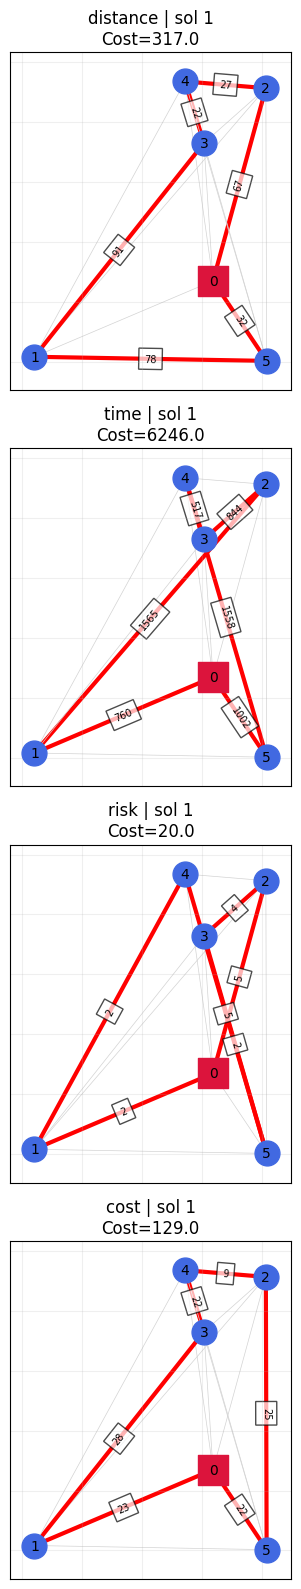

In [29]:
def visualize_route(opt_x, info, ax=None, title=""):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))

    depot = info["depot"]
    EMPTY = info["EMPTY"]
    coords = info["coords"]
    c_core = info["c_core"]
    x_index = info["x_index"]

    # -------------------------
    # Reconstruir rotas por veículo
    # -------------------------
    routes = []

    K = max(k for (_, k, _) in x_index.keys())
    T = info["T"]

    for k in range(1, K+1):
        route = []

        for t in range(0, T+1):
            for i in info["N"]:
                idx = x_index[(i, k, t)]
                if opt_x[idx] == 1:
                    route.append(i)
                    break

        # remover EMPTY
        route = [i for i in route if i != EMPTY]

        # ignorar rotas triviais
        if len(route) > 1:
            routes.append(route)

    # -------------------------
    # Calcular custo real
    # -------------------------
    custo_real = 0.0
    edges_solution = []

    for route in routes:
        for i in range(len(route) - 1):
            u, v = route[i], route[i+1]
            custo_real += c_core[u, v]
            edges_solution.append((u, v))

        # retorno ao depósito
        if route[-1] != depot:
            custo_real += c_core[route[-1], depot]
            edges_solution.append((route[-1], depot))

    # -------------------------
    # Construir grafo
    # -------------------------
    n_nodes = len(coords)

    G = nx.Graph()
    for i in range(n_nodes):
        G.add_node(i, pos=(coords[i, 0], coords[i, 1]))

    # todas arestas (cinza)
    for i in range(n_nodes):
        for j in range(i + 1, n_nodes):
            G.add_edge(i, j, weight=int(c_core[i, j]), color='lightgray', width=0.5)

    # solução (vermelho)
    for (i, j) in edges_solution:
        if G.has_edge(i, j):
            G[i][j]['color'] = 'red'
            G[i][j]['width'] = 3
        else:
            G.add_edge(i, j, weight=int(c_core[i, j]), color='red', width=3)

    pos = {i: (coords[i, 0], coords[i, 1]) for i in range(n_nodes)}

    edges = G.edges()
    colors = [G[u][v]['color'] for u, v in edges]
    widths = [G[u][v]['width'] for u, v in edges]

    nx.draw_networkx_nodes(G, pos, nodelist=[depot],
                           node_color="crimson", node_shape="s", node_size=450, ax=ax)
    nx.draw_networkx_nodes(G, pos,
                           nodelist=[i for i in range(n_nodes) if i != depot],
                           node_color="royalblue", node_shape="o", node_size=320, ax=ax)

    nx.draw_networkx_edges(G, pos, edge_color=colors, width=widths, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=10, ax=ax)

    # labels só da solução
    edge_labels = {(u, v): int(c_core[u, v]) for (u, v) in edges_solution}

    nx.draw_networkx_edge_labels(
        G, pos,
        edge_labels=edge_labels,
        font_size=7,
        bbox=dict(facecolor='white', alpha=0.7),
        ax=ax
    )

    ax.set_title(f"{title}\nCost={custo_real}")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)

def plot_all_solutions_grid(solutions, qubo_models):
    instance_names = list(solutions.keys())

    # número máximo de soluções ótimas em qualquer instância
    max_solutions = max(len(solutions[name]["opt_x_list"]) for name in instance_names)

    n_rows = len(instance_names)
    n_cols = max_solutions

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))

    # garantir que axes é 2D
    if n_rows == 1:
        axes = np.array([axes])
    if n_cols == 1:
        axes = axes.reshape(-1, 1)

    for i, name in enumerate(instance_names):
        opt_list = solutions[name]["opt_x_list"]
        info = qubo_models[name]["info"]

        for j in range(n_cols):
            ax = axes[i, j]

            if j < len(opt_list):
                visualize_route(
                    opt_list[j],
                    info,
                    ax=ax,
                    title=f"{name} | sol {j+1}"
                )
            else:
                ax.axis("off")

    plt.tight_layout()
    plt.show()

plot_all_solutions_grid(solutions, qubo_models)

## Check Solution

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import math

# =========================================================
# 🔹 Helper: extrair rotas da solução x
# =========================================================
def extract_routes(x, info):
    x_index = info["x_index"]
    N = info["N"]
    K = max(k for (_, k, _) in x_index.keys())
    T = info["T"]
    EMPTY = info["EMPTY"]

    routes = []

    for k in range(1, K+1):
        route = []

        for t in range(0, T+1):
            for i in N:
                idx = x_index[(i, k, t)]
                if x[idx]:
                    route.append(i)
                    break

        # remover EMPTY
        route = [i for i in route if i != EMPTY]

        if len(route) > 1:
            routes.append(route)

    return routes


# =========================================================
# 🔹 Cálculo de custo
# =========================================================
def compute_all_costs(x, info, instances):
    costs = {name: 0 for name in instances}

    depot = info["depot"]

    routes = extract_routes(x, info)

    for name, matrix in instances.items():
        for route in routes:

            # custo ao longo da rota
            for i in range(len(route) - 1):
                costs[name] += matrix[route[i], route[i+1]]

            # retorno ao depósito
            if route[-1] != depot:
                costs[name] += matrix[route[-1], depot]

    return costs


# =========================================================
# 🔹 Visualização
# =========================================================
def visualize_route(x, info, ax=None, title=""):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))

    coords = info["coords"]
    c_core = info["c_core"]
    depot = info["depot"]

    routes = extract_routes(x, info)

    # -------------------------
    # custo
    # -------------------------
    custo_real = 0
    edges_solution = []

    for route in routes:
        for i in range(len(route) - 1):
            u, v = route[i], route[i+1]
            custo_real += c_core[u, v]
            edges_solution.append((u, v))

        if route[-1] != depot:
            custo_real += c_core[route[-1], depot]
            edges_solution.append((route[-1], depot))

    # -------------------------
    # grafo
    # -------------------------
    n_nodes = len(coords)

    G = nx.Graph()
    for i in range(n_nodes):
        G.add_node(i, pos=(coords[i, 0], coords[i, 1]))

    for i in range(n_nodes):
        for j in range(i + 1, n_nodes):
            G.add_edge(i, j, weight=int(c_core[i, j]), color='lightgray', width=0.5)

    for (i, j) in edges_solution:
        if G.has_edge(i, j):
            G[i][j]['color'] = 'red'
            G[i][j]['width'] = 3
        else:
            G.add_edge(i, j, weight=int(c_core[i, j]), color='red', width=3)

    pos = {i: (coords[i, 0], coords[i, 1]) for i in range(n_nodes)}

    edges = G.edges()
    colors = [G[u][v]['color'] for u, v in edges]
    widths = [G[u][v]['width'] for u, v in edges]

    nx.draw_networkx_nodes(G, pos, nodelist=[depot],
                           node_color="crimson", node_shape="s", node_size=450, ax=ax)

    nx.draw_networkx_nodes(G, pos,
                           nodelist=[i for i in range(n_nodes) if i != depot],
                           node_color="royalblue", node_shape="o", node_size=320, ax=ax)

    nx.draw_networkx_edges(G, pos, edge_color=colors, width=widths, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=10, ax=ax)

    edge_labels = {(u, v): int(c_core[u, v]) for (u, v) in edges_solution}

    nx.draw_networkx_edge_labels(
        G, pos,
        edge_labels=edge_labels,
        font_size=7,
        bbox=dict(facecolor='white', alpha=0.7),
        ax=ax
    )

    ax.set_title(f"{title}\nCost={custo_real}")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)


# =========================================================
# 🔹 Plot de múltiplas soluções
# =========================================================
def plot_maxcut_solutions(x_list, info, instances, title_prefix="SOL"):
    max_cols = 4
    n = len(x_list)

    n_cols = min(max_cols, n)
    n_rows = math.ceil(n / max_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))

    if n_rows == 1:
        axes = np.array([axes])
    if n_cols == 1:
        axes = axes.reshape(-1, 1)

    for idx_sol, x in enumerate(x_list):
        row = idx_sol // max_cols
        col = idx_sol % max_cols

        ax = axes[row, col]

        costs = compute_all_costs(x, info, instances)

        cost_str = "(" + ", ".join([
            f"{k[:4]}={v}" for k, v in costs.items()
        ]) + ")"

        visualize_route(
            x,
            info,
            ax=ax,
            title=f"{title_prefix} {idx_sol+1}\n{cost_str}"
        )

    # desligar eixos vazios
    total_plots = n_rows * n_cols
    for k in range(n, total_plots):
        row = k // max_cols
        col = k % max_cols
        axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()


def plot_maxcut_matrix(Z, info, instances):
    z_list = [Z[i] for i in range(Z.shape[0])]
    plot_maxcut_solutions(z_list, info, instances)


# =========================================================
# 🔹 Canonicalização e remoção de duplicatas
# =========================================================
def canonicalize_and_deduplicate(solutions, info):

    def canonicalize_route(route):
        forward = tuple(route)
        backward = tuple(route[::-1])
        return min(forward, backward)

    def canonicalize_solution(routes):
        canon_routes = [canonicalize_route(r) for r in routes]
        return tuple(sorted(canon_routes))

    solutions = np.array(solutions, dtype=np.int8)

    # -------------------------
    # remover gauge
    # -------------------------
    last_bit = solutions[:, -1]
    core = solutions[:, :-1].copy()

    flip_mask = last_bit == 1
    core[flip_mask] = 1 - core[flip_mask]

    # -------------------------
    # remover duplicatas
    # -------------------------
    seen = set()
    unique = []

    for x in core:
        routes = extract_routes(x, info)
        canonical = canonicalize_solution(routes)

        if canonical not in seen:
            seen.add(canonical)
            unique.append(x)

    return np.array(unique, dtype=np.int8)

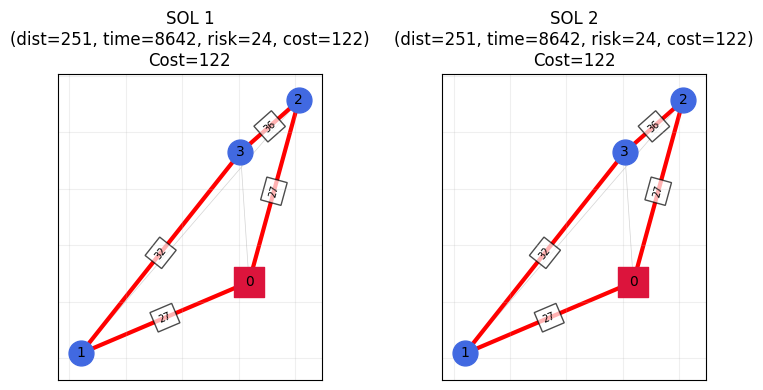

In [12]:
list_of_solutions = [[0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1]]

list_of_solutions_unique = canonicalize_and_deduplicate(list_of_solutions, info)
plot_maxcut_solutions(list_of_solutions_unique, info, instances)

# 7) QUBO to Max-Cut Reduction

We convert a QUBO problem

$$
\max_{x \in \{0,1\}^n} x^T Q x
$$

into an equivalent **Max-Cut** problem on a graph with **$n+1$ vertices**. This transformation follows the construction proposed by Bhattacharyya *et al.* (2025), where an auxiliary vertex is introduced to eliminate the linear terms that appear when mapping binary variables $\{0,1\}$ into Ising spins $\{-1,1\}$.

The adjacency matrix $A$ of the Max-Cut graph is constructed from the QUBO matrix $Q$ as

$$
A_{i,j} = -Q_{i,j}, \quad
A_{n,i} = \sum_{j=0}^{n-1} Q_{i,j}, \quad
A_{n,n} = 0.
$$

Solving the Max-Cut problem on this graph is energetically equivalent to solving the original QUBO. The extra vertex (the last one) is an auxiliary node introduced by the reduction and plays a special role in warm-start QAOA methods.


In [59]:
def normalize_qubo(Q):
    Q = np.array(Q, dtype=float)
    max_abs = np.max(np.abs(Q))
    if max_abs > 0:
        Q = Q / max_abs
    return Q

def qubo_to_maxcut_matrix(Q):
    """
    Convert QUBO matrix Q (n x n) to Max-Cut adjacency matrix A (n+1 x n+1)
    following the paper mapping.
    """
    n = Q.shape[0]
    A = np.zeros((n+1, n+1))

    # Edges between original variables
    for i in range(n):
        for j in range(i+1, n):
            A[i, j] = A[j, i] = -Q[i, j]

    # Edges to auxiliary node
    row_sums = Q.sum(axis=1)
    for i in range(n):
        A[i, n] = A[n, i] = row_sums[i]

    np.fill_diagonal(A, 0)
    return A

maxcut_models = {}

for name, model in qubo_models.items():
    print(f"\nConverting QUBO → MAXCUT: {name.upper()}")

    Q = model["Q"]

    # 1. simetrizar
    Q_sym = (Q + Q.T) / 2.0

    # 2. transformar em problema de maximização
    Qmax = -Q_sym

    # 3. normalizar
    Q_norm = normalize_qubo(Qmax)

    # 4. converter para MAXCUT
    A = qubo_to_maxcut_matrix(Q_norm)

    # salvar tudo
    maxcut_models[name] = {
        "Q_sym": Q_sym,
        "Qmax": Qmax,
        "Q_norm": Q_norm,
        "A": A
    }

    print(f"A shape: {A.shape}")


Converting QUBO → MAXCUT: DISTANCE
A shape: (21, 21)

Converting QUBO → MAXCUT: TIME
A shape: (21, 21)

Converting QUBO → MAXCUT: RISK
A shape: (21, 21)

Converting QUBO → MAXCUT: COST
A shape: (21, 21)


This cell converts the adjacency matrix we created earlier to JSON format.

In [60]:
import json, os

def adjacency_matrix_to_json(A, filename="graph.json"):
    """
    Converts a weighted adjacency matrix to JSON-compatible format.

    Parameters:
    -----------
    A : list of list or np.ndarray
        n x n adjacency matrix, where A[i][j] is the weight of edge (i, j).
        If A[i][j] = 0, no edge is created (unless zero weights are valid).
        Matrix is assumed symmetric for undirected graphs.
    filename : str
        Output file name.
    """
    n = len(A)
    
    # Create list of nodes
    nodes = [{"id": i} for i in range(n)]
    
    # Create list of edges (links)
    links = []
    for i in range(n):
        # For undirected graphs, only traverse j > i to avoid duplication
        for j in range(i + 1, n):
            weight = A[i][j]
            # If you want to include edges with weight 0, remove the condition below
            if weight != 0:
                links.append({
                    "weight": float(weight),
                    "source": i,
                    "target": j
                })
    
    # Build final dictionary
    graph_data = {
        "directed": False,
        "multigraph": False,
        "graph": {},
        "nodes": nodes,
        "links": links
    }
    
    os.makedirs(os.path.dirname(filename), exist_ok=True)
    
    # Save to JSON file
    with open(filename, 'w', encoding='utf-8') as f:
        json.dump(graph_data, f, indent=2, ensure_ascii=False)
    
    print(f"File saved as {filename}")
    return graph_data
    
base_path = "../qamoo/data/problems"

for idx, (name, model) in enumerate(maxcut_models.items()):
    print(f"\nSaving {name} as problem_graph_{idx}.json")

    A = model["A"]

    # número de qubits = n + 1 (por causa do nó auxiliar)
    n_qubits = A.shape[0]

    filename = (
        f"{base_path}/"
        f"{n_qubits}q/"
        f"problem_set_{n_qubits}q_10s_3o_0/"
        f"problem_graph_{idx}.json"
    )

    adjacency_matrix_to_json(A, filename)


Saving distance as problem_graph_0.json
File saved as ../qamoo/data/problems/21q/problem_set_21q_10s_3o_0/problem_graph_0.json

Saving time as problem_graph_1.json
File saved as ../qamoo/data/problems/21q/problem_set_21q_10s_3o_0/problem_graph_1.json

Saving risk as problem_graph_2.json
File saved as ../qamoo/data/problems/21q/problem_set_21q_10s_3o_0/problem_graph_2.json

Saving cost as problem_graph_3.json
File saved as ../qamoo/data/problems/21q/problem_set_21q_10s_3o_0/problem_graph_3.json
